# Prática com os *Pipelines* do Hugging Face 🤗

Acesse em https://huggingface.co:

- [Pipelines](https://huggingface.co/docs/transformers/main_classes/pipelines)
- [Tasks](https://huggingface.co/tasks)

<br>

Este notebook apresenta alguns **exemplos mínimos** de uso de modelos de linguagem abertos e pequenos, em **português**:

| # | Tarefa | Biblioteca/Pipeline |
|---|--------|---------------------|
| 1 | Chat simples | `text-generation` |
| 2 | Chat com contexto | `text-generation` |
| 3 | Resumo de texto | `text-generation` |
| 4 | Classificação *zero-shot* | `zero-shot-classification` |
| 5 | Classificação de textos | `text-classification` |
| 6 | Geração de áudio  | `text-to-audio` |
| 7 | Segmentação de imagens | `image segmentation` |
| 8 | Geração de imagens | `text-to-image` |

<br>

**Antes de começar**

1. Ative a GPU gratuita do Colab
2. Se os modelos ocuparem toda memória (incluindo a da GPU) do seu notebook, empregue o código abaixo para limpar a memória e execute somente as células necessárias

In [ ]:
%%script echo off
import torch
import gc

if 'chat' in globals():
    del chat
if 'pipe' in globals():
    del pipe

# 2. Chamar o coletor de lixo do Python para limpar a memória RAM
gc.collect()

# 3. Limpar o cache da GPU no PyTorch
if torch.cuda.is_available():
    torch.cuda.empty_cache()
    print("Memória da GPU liberada com sucesso!")
else:
    print("GPU não disponível ou já liberada.")

Memória da GPU liberada com sucesso!


# 0. Preparação do ambiente

A célula abaixo instala os pacotes necessários:

- `transformers`: biblioteca principal, que contém os *pipelines*;
- `accelerate`: auxilia o carregamento eficiente dos modelos;
- `sentencepiece` e `protobuf`: necessários para o tokenizador do modelo de classificação.

O PyTorch (`torch`) já vem instalado no Colab.

In [1]:
!pip install -q transformers accelerate sentencepiece protobuf

In [2]:
import torch
import transformers
from transformers import pipeline

print("Versão do transformers:", transformers.__version__)
print("GPU disponível:", torch.cuda.is_available())

# Dispositivo: 0 = primeira GPU, -1 = CPU
DEVICE = 0 if torch.cuda.is_available() else -1
# Em GPU usamos meia precisão (float16) para economizar memória
DTYPE = torch.float16 if torch.cuda.is_available() else torch.float32

Versão do transformers: 5.22.1
GPU disponível: True


# Introdução ao *pipeline* do Hugging Face

Usar um modelo de linguagem "por baixo dos panos" exige várias etapas:

1. **Pré-processamento**: o texto é convertido em números (*tokens*) por um **tokenizador**;
2. **Modelo**: a rede neural recebe os tokens e produz uma saída numérica;
3. **Pós-processamento**: a saída numérica é convertida de volta em algo legível (texto, rótulos, probabilidades).

A função `pipeline()` da biblioteca `transformers` **empacota essas três etapas** em um único objeto, que pode ser chamado como se fosse uma função. O uso geral tem sempre a mesma forma:

```python
from transformers import pipeline

meu_pipeline = pipeline("nome-da-tarefa", model="organizacao/nome-do-modelo")
resultado = meu_pipeline(entrada, **parametros_opcionais)
```

- **`"nome-da-tarefa"`** diz *o que* queremos fazer (por exemplo, `text-generation` ou `zero-shot-classification`). A tarefa determina o formato da entrada e da saída.
- **`model="..."`** diz *qual modelo* usar. Ele é o identificador de um modelo publicado no [Hugging Face Hub](https://huggingface.co/models), que é baixado automaticamente na primeira vez. Cada modelo tem uma página (*model card*) com descrição, idiomas suportados e licença.
- Parâmetros como `device` (GPU/CPU) e `dtype` (precisão numérica) são informados na criação do pipeline; parâmetros de uso, como `max_new_tokens`, são informados na chamada.

### Observações

- **Resumo sem o pipeline `summarization`**: nas versões 5 em diante do `transformers`, os pipelines `summarization`, `translation` e `text2text-generation` foram removidos. A abordagem recomendada hoje é pedir o resumo a um modelo de chat por meio de um *prompt*, e é isso que faremos na Tarefa 3. Assim, o notebook funciona tanto na versão 4 quanto na 5 da biblioteca.
- **Modelos pequenos**: Aqui empregamos somente modelos pequenos e abertos. Eles são ótimos para aprender e experimentar, mas podem cometer erros e levar a resultados nem sempre tão bons como modelos maiores.

## 1. Chat simples

É uma interação de *uma pergunta → uma resposta*, sem memória de interações anteriores.

Usamos o pipeline `text-generation` com um **modelo de chat** (*instruct*). Em vez de passar uma string, passamos uma **lista de mensagens**, cada uma com:

- `role` (papel): `"system"` (instruções gerais de comportamento), `"user"` (o usuário) ou `"assistant"` (o modelo);
- `content` (conteúdo): o texto da mensagem.

O pipeline aplica automaticamente o *template de chat* próprio do modelo. A saída é a lista de mensagens **acrescida da resposta do modelo**, que é a última mensagem.

Parâmetros:
- `max_new_tokens`: limite de tokens que o modelo pode gerar (evita respostas intermináveis);
- `do_sample=False`: resposta determinística (sempre a mais provável). Com `do_sample=True`, a resposta tem aleatoriedade e varia a cada execução.

In [3]:
MODELO_CHAT = "Qwen/Qwen2.5-1.5B-Instruct"

chat = pipeline(
    "text-generation",
    model=MODELO_CHAT,
    dtype=DTYPE,
    device=DEVICE,
)

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

In [4]:
mensagens = [
    {"role": "system", "content": "Você é um assistente prestativo que responde sempre em português do Brasil, de forma clara e concisa."},
    {"role": "user", "content": "Explique em duas frases o que é um modelo de linguagem."},
]

saida = chat(mensagens, max_new_tokens=150, do_sample=False)

# A saída traz a conversa completa; a resposta do modelo é a última mensagem
resposta = saida[0]["generated_text"][-1]["content"]
print(resposta)

Um modelo de linguagem é uma estrutura computacional usada para codificar e interpretar a gramática natural da língua humana. Ele permite que sistemas informáticos entendam e produzam textos humanamente fluídos.

Em outras palavras, um modelo de linguagem é como um dicionário digital que aprende com os dados de texto fornecidos por usuários ou treinados por especialistas. Isso permite que ele reconheça padrões na fala e escrita humana, ajudando a criar programas capazes de entender e responder de maneira mais próxima à comunicação oral e escrita dos seres humanos.


**Experimente:** troque o conteúdo da mensagem do usuário por outra pergunta e execute novamente. Teste também `do_sample=True, temperature=0.7` e observe que a resposta muda a cada execução.

## 2. Chat com contexto

Aqui implementamos uma conversa em que o modelo "lembra" do que foi dito antes.

O modelo **não tem memória própria**. Cada chamada é independente. Para simular memória, nós mantemos o **histórico** da conversa (a lista de mensagens) e **reenviamos tudo** a cada nova pergunta, acrescentando:

1. a nova mensagem do usuário ao histórico;
2. a resposta do modelo ao histórico, depois de gerada.

Abaixo, a função `conversar()` faz esse trabalho. Em seguida, comparamos com o que acontece **sem** histórico.

In [5]:
historico = [
    {"role": "system", "content": "Você é um assistente prestativo que responde sempre em português do Brasil, de forma clara e concisa."},
]

def conversar(historico, texto_usuario, max_new_tokens=150):
    # 1) acrescenta a fala do usuário ao histórico
    historico.append({"role": "user", "content": texto_usuario})
    # 2) envia o histórico COMPLETO ao modelo
    saida = chat(historico, max_new_tokens=max_new_tokens, do_sample=False)
    resposta = saida[0]["generated_text"][-1]["content"]
    # 3) guarda a resposta do modelo no histórico
    historico.append({"role": "assistant", "content": resposta})
    return resposta

print("Usuário: Olá! Meu nome é Ana, moro em Recife e estudo biologia.")
print("Modelo :", conversar(historico, "Olá! Meu nome é Ana, moro em Recife e estudo biologia."))

print("\nUsuário: Qual é o meu nome e o que eu estudo?")
print("Modelo :", conversar(historico, "Qual é o meu nome e o que eu estudo?"))

Usuário: Olá! Meu nome é Ana, moro em Recife e estudo biologia.
Modelo : Olá Ana! Fico feliz por você estudar biologia em Recife. Como posso ajudar você hoje?

Usuário: Qual é o meu nome e o que eu estudo?
Modelo : Seu nome é Ana e está estudando biologia.


**Para comparar:** a mesma pergunta feita **sem** o histórico. O modelo não tem como saber a resposta.

In [6]:
sem_contexto = [
    {"role": "system", "content": "Você é um assistente prestativo que responde sempre em português do Brasil, de forma clara e concisa."},
    {"role": "user", "content": "Qual é o meu nome e o que eu estudo?"},
]
saida = chat(sem_contexto, max_new_tokens=100, do_sample=False)
print(saida[0]["generated_text"][-1]["content"])

Desculpe pela confusão, mas como assistente virtual, não tenho acesso a informações pessoais sobre você ou seu histórico escolar. Eu sou projetado para fornecer assistência geral e responder perguntas de maneira geralizada. Se você tiver alguma dúvida específica sobre seus dados pessoais ou sua formação acadêmica, seria melhor falar diretamente com alguém que possa ter essas informações.


Podemos inspecionar o histórico acumulado para ver exatamente o que foi enviado ao modelo:

In [7]:
for m in historico:
    print(f"[{m['role']}] {m['content']}\n")

[system] Você é um assistente prestativo que responde sempre em português do Brasil, de forma clara e concisa.

[user] Olá! Meu nome é Ana, moro em Recife e estudo biologia.

[assistant] Olá Ana! Fico feliz por você estudar biologia em Recife. Como posso ajudar você hoje?

[user] Qual é o meu nome e o que eu estudo?

[assistant] Seu nome é Ana e está estudando biologia.



**Opcional: conversa interativa.** A célula abaixo abre uma caixa de texto para você conversar com o modelo. Digite `sair` para encerrar.

> Lembre-se: quanto mais longa a conversa, maior o histórico enviado a cada chamada, e todo modelo tem um limite de contexto.

In [8]:
historico_interativo = [
    {"role": "system", "content": "Você é um assistente prestativo que responde sempre em português do Brasil, de forma clara e concisa."},
]

while True:
    entrada = input("Você: ")
    if entrada.strip().lower() == "sair":
        print("Conversa encerrada.")
        break
    print("Modelo:", conversar(historico_interativo, entrada), "\n")

Você: Pode me dizer o que é "model drift" em aprendizado de máquina?
Modelo: Claro! O termo "model drift" refere-se a uma mudança no comportamento ou na qualidade de um modelo de machine learning ao longo do tempo. Isso ocorre quando os dados usados para treinar o modelo não mais refletem as características reais da realidade, levando à deterioração da precisão do modelo.

Em outras palavras, model drift pode ser entendido como uma variação nos padrões de entrada dos dados que o modelo está sendo treinado, causando assim uma queda na eficácia do modelo em prever novos dados. É importante identificar e corrigir este fenômeno para garantir que o modelo continue a funcionar adequadamente com novas entr 

Você: sair
Conversa encerrada.


## 3. Resumo de texto

A ideia de um resumo de texto é condensar um texto longo em uma versão curta, mantendo as ideias principais.

O pipeline `summarization` não existe mais nas versões recentes do `transformers`. Em vez dele, usamos o **mesmo modelo de chat** da Tarefa 1 e damos a instrução de resumir **no próprio *prompt***. Isso é possível porque modelos *instruct* são treinados para seguir instruções.

A qualidade do resumo depende muito do *prompt*. Algumas boas práticas:

- diga claramente a tarefa ("Resuma o texto abaixo");
- defina o **formato e o tamanho** ("em no máximo 3 frases", "em 3 tópicos");
- indique o idioma da resposta;
- separe a instrução do texto com um marcador claro.

In [9]:
texto = '''
A inteligência artificial tem sido incorporada gradualmente às escolas e universidades brasileiras.
Ferramentas baseadas em modelos de linguagem permitem que estudantes tirem dúvidas fora do horário de aula,
recebam sugestões de revisão de textos e pratiquem outros idiomas. Para os professores, esses sistemas
podem ajudar na elaboração de planos de aula, na criação de exercícios e na correção de tarefas repetitivas,
liberando tempo para atividades de maior valor pedagógico. Apesar dos benefícios, especialistas alertam
para riscos importantes: respostas incorretas apresentadas com muita confiança, dependência excessiva da
ferramenta, desigualdade de acesso à tecnologia e dúvidas sobre privacidade dos dados dos alunos. Por isso,
defende-se que o uso da IA seja acompanhado de formação docente, de orientações claras sobre uso ético e de
atividades que estimulem o pensamento crítico, em vez de substituir o esforço de aprendizagem dos estudantes.
'''

prompt = (
    "Resuma o texto abaixo em no máximo 3 frases, em português do Brasil.\n\n"
    f"Texto:\n{texto}"
)

mensagens = [
    {"role": "system", "content": "Você é um assistente especializado em resumir textos de forma fiel e objetiva."},
    {"role": "user", "content": prompt},
]

saida = chat(mensagens, max_new_tokens=200, do_sample=False)
print(saida[0]["generated_text"][-1]["content"])

O AI está sendo integrado nas escolas e universidades brasileiras, permitindo que os alunos tenham acesso a ferramentas como revisão de textos e prática de idiomas. Os professores podem auxiliar na planejamento, criando atividades mais valiosas e liberando tempo para atividades educacionais mais significativas. No entanto, há preocupações sobre a qualidade das respostas, dependência excessiva da tecnologia, desigualdades de acesso e questões de privacidade. Portanto, é importante combinar o uso do AI com formação docente adequada e atividades que promovam o pensamento crítico.


**Experimente:** altere a instrução para pedir o resumo **em 3 tópicos** (`"Resuma o texto abaixo em 3 tópicos curtos"`) ou **em uma única frase para uma criança de 10 anos**, e compare os resultados. Ou ainda dê uma instrução de resumo não tão clara.

## 4. Classificação *zero-shot*

Vamos agora classificar um texto em categorias **que o modelo nunca viu durante o treinamento para essa tarefa**. Nós simplesmente fornecemos o texto e uma lista de rótulos candidatos, **sem precisar de dados de treino rotulados**.

O pipeline `zero-shot-classification` usa um modelo de **inferência de linguagem natural (NLI)**, treinado para decidir se uma *premissa* implica uma *hipótese*. Para cada rótulo candidato, o pipeline monta uma hipótese a partir de um **modelo de frase** (*hypothesis template*) e verifica o quanto o texto a sustenta. Por exemplo, para o rótulo `esportes`:

> Premissa (o texto): *"O Palmeiras venceu o clássico por 2 a 0..."*
> Hipótese: *"Este texto é sobre esportes."*

Os rótulos são ordenados pela pontuação obtida. Parâmetros importantes:

- `candidate_labels`: lista de categorias possíveis (você escolhe!);
- `hypothesis_template`: frase com `{}` onde entra o rótulo. **Para textos em português, use um template em português.** O padrão é em inglês;
- `multi_label`: se `False` (padrão), as pontuações somam 1 e há uma categoria "vencedora"; se `True`, cada rótulo é avaliado independentemente (um texto pode pertencer a várias categorias).

In [10]:
MODELO_ZS = "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"

classificador = pipeline(
    "zero-shot-classification",
    model=MODELO_ZS,
    device=DEVICE,
)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

... (2 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

### 4.1 Classificação por tema (um único rótulo)

In [11]:
texto = "O Palmeiras venceu o clássico por 2 a 0 e assumiu a liderança do campeonato brasileiro."
rotulos = ["esportes", "política", "economia", "tecnologia", "saúde"]

resultado = classificador(
    texto,
    candidate_labels=rotulos,
    hypothesis_template="Este texto é sobre {}.",
)

print("Texto:", resultado["sequence"], "\n")
for rotulo, pontuacao in zip(resultado["labels"], resultado["scores"]):
    print(f"{rotulo:<12} {pontuacao:.1%}")

Texto: O Palmeiras venceu o clássico por 2 a 0 e assumiu a liderança do campeonato brasileiro. 

esportes     99.8%
saúde        0.1%
tecnologia   0.0%
economia     0.0%
política     0.0%


### 4.2 Análise de sentimento (outro conjunto de rótulos, mesmo modelo)

A grande vantagem do *zero-shot* é a flexibilidade: basta trocar os rótulos e o *template* para resolver outra tarefa, sem treinar nada.

In [12]:
avaliacoes = [
    "Adorei o atendimento, a comida chegou quentinha e antes do prazo!",
    "O produto chegou quebrado e ninguém me ajudou a resolver o problema.",
]

for avaliacao in avaliacoes:
    res = classificador(
        avaliacao,
        candidate_labels=["positivo", "negativo", "neutro"],
        hypothesis_template="O sentimento deste texto é {}.",
    )
    print(f"{avaliacao}\n  → {res['labels'][0]} ({res['scores'][0]:.1%})\n")

Adorei o atendimento, a comida chegou quentinha e antes do prazo!
  → positivo (91.3%)

O produto chegou quebrado e ninguém me ajudou a resolver o problema.
  → negativo (65.7%)



### 4.3 Vários rótulos ao mesmo tempo (`multi_label=True`)

Um mesmo texto pode tratar de mais de um assunto. Com `multi_label=True`, cada rótulo recebe uma pontuação independente (que **não** soma 1).

In [13]:
texto = "O governo anunciou um novo programa de incentivo fiscal para startups de inteligência artificial."
rotulos = ["política", "economia", "tecnologia", "esportes", "saúde"]

resultado = classificador(
    texto,
    candidate_labels=rotulos,
    hypothesis_template="Este texto é sobre {}.",
    multi_label=True,
)

for rotulo, pontuacao in zip(resultado["labels"], resultado["scores"]):
    print(f"{rotulo:<12} {pontuacao:.1%}")

política     100.0%
tecnologia   100.0%
economia     99.9%
saúde        0.0%
esportes     0.0%


## 5. Classificação *text-classification*

Utiliza um modelo que foi treinado (ou fine-tuned) em um conjunto fixo e pré-determinado de classes (por exemplo, POSITIVO e NEGATIVO para análise de sentimentos, ou tópicos fixos como esportes, economia).

**É diferente do `zero-shot-classification**, que usa um modelo de NLI (Inferência em Linguagem Natural, premissa $⟶$ hipótese).

> Nota: nem sempre precisamos indicar a tarefa.


In [14]:
pipe = pipeline("text-classification")
pipe("Este curso foi muito legal!")

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9180000424385071}]

## 6. Multi-modal *text-to-audio*

In [22]:
from transformers import pipeline

pipe = pipeline(model="suno/bark-small")
output = pipe("Agora entendo um pouco mais sobre os modelos de linguagem!")

audio = output["audio"]
sampling_rate = output["sampling_rate"]

config.json:   0%|          | 0.00/8.80k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.68GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/542 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/4.91k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/353 [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/2.92M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

speaker_embeddings_path.json:   0%|          | 0.00/61.1k [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'min_eos_p'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=768) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=60) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/t

In [27]:
import scipy
scipy.io.wavfile.write("audio_output.wav", rate=sampling_rate, data=audio)

**Experimente:** Use o modelo `facebook/musicgen-small` para gerar música a partir de textos.

## 7. Image *Segmentation*

Há várias tarefas bastante úteis para imagens, como detecção de objetos, classificação etc. Mas veremos isso na segunda parte do curso. Aqui, apenas um exemplo com segmentação e no seguinte de geração de imagens.

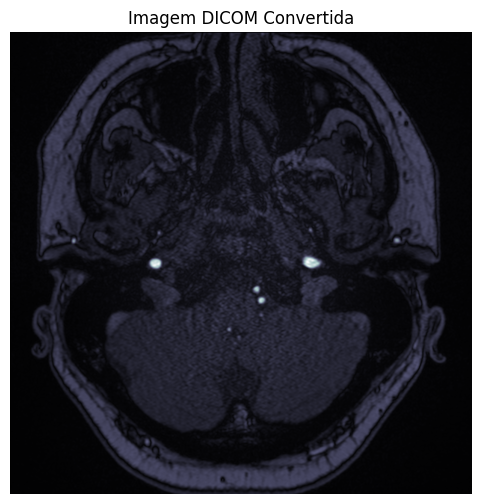

In [28]:
!pip install -q pydicom requests

import requests
import pydicom
import matplotlib.pyplot as plt
from io import BytesIO

# URL do arquivo DICOM
url = "https://github.com/PPGCA-MLG/2026S2/raw/refs/heads/main/Aula_06/IM-0001-0086.dcm"

# Baixando o arquivo
response = requests.get(url)
if response.status_code == 200:
    # Lendo o arquivo DICOM a partir dos bytes na memória
    dicom_data = pydicom.dcmread(BytesIO(response.content))

    # Extraindo a matriz de pixels
    image_array = dicom_data.pixel_array

    # Exibindo a imagem
    plt.figure(figsize=(6, 6))
    plt.imshow(image_array, cmap=plt.cm.bone)
    plt.title("Imagem DICOM Convertida")
    plt.axis("off")
    plt.show()
else:
    print("Não foi possível baixar o arquivo DICOM. Status:", response.status_code)

In [29]:
import matplotlib.pyplot as plt
import os

# Caminho onde a imagem será salva
caminho_destino = "/content/imagem_convertida.png"

# Normalizando e salvando a matriz de pixels como uma imagem PNG utilizando um mapa de cores (cmap) adequado
plt.imsave(caminho_destino, image_array, cmap=plt.cm.bone)

# Verificando se o arquivo foi criado corretamente
if os.path.exists(caminho_destino):
    print(f"Sucesso! A imagem foi salva em: {caminho_destino}")
else:
    print("Erro ao tentar gravar a imagem.")

Sucesso! A imagem foi salva em: /content/imagem_convertida.png


In [50]:
from transformers import pipeline

segmenter = pipeline(model="facebook/detr-resnet-50-panoptic")
segments = segmenter("https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcSh6dm4xtjtLPihOFU-NVAmQQT4vRa-1rM9fR7gZ7y_vw&s=10")
len(segments)

segments[0]["label"]


Loading weights:   0%|          | 0/562 [00:00<?, ?it/s]

'car'

In [51]:
segments

[{'score': 0.998846,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.979291,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.979553,
  'label': 'LABEL_191',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.986666,
  'label': 'road',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.903834,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.924735,
  'label': 'car',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.997408,
  'label': 'LABEL_184',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.996647,
  'label': 'LABEL_187',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.999584,
  'label': 'person',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.999726,
  'label': 'person',
  'mask': <PIL.Image.Image image mode=L size=447x447>},
 {'score': 0.91918,
  'la

In [55]:
%%script echo off
import matplotlib.pyplot as plt

# Vamos criar uma figura para exibir cada segmento detectado
fig, axes = plt.subplots(1, len(segments), figsize=(15, 5))

# Se houver apenas 1 elemento, 'axes' não será uma lista, então ajustamos
if len(segments) == 1:
    axes = [axes]

for i, seg in enumerate(segments):
    axes[i].imshow(seg["mask"], cmap="gray")
    axes[i].set_title(f"{seg['label']} ({seg['score']:.1%})")
    axes[i].axis("off")

plt.tight_layout()
plt.show()

off


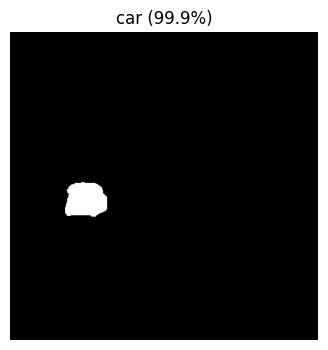

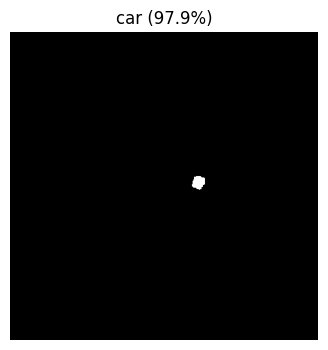

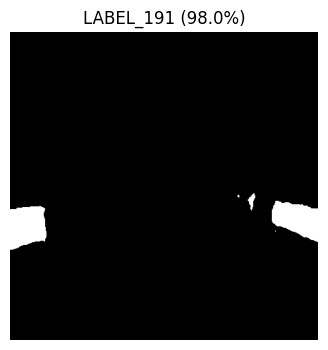

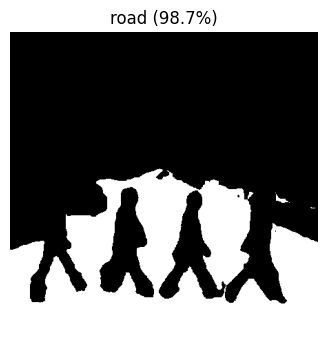

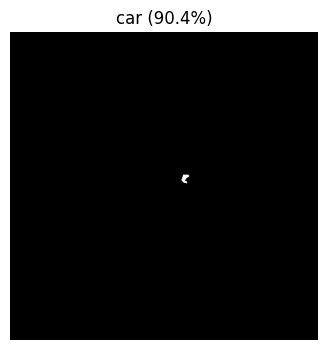

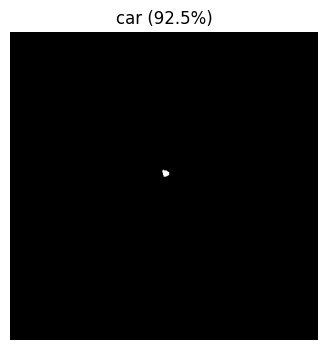

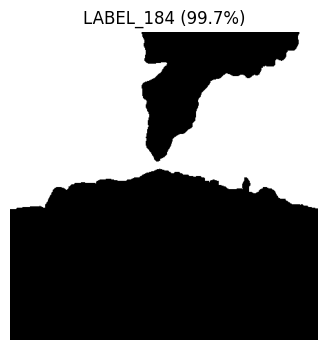

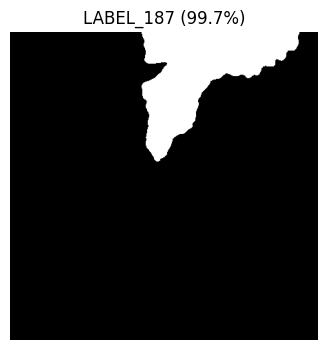

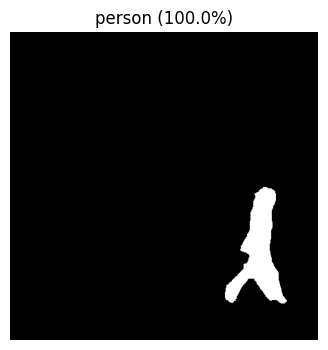

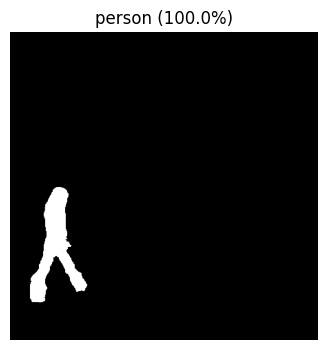

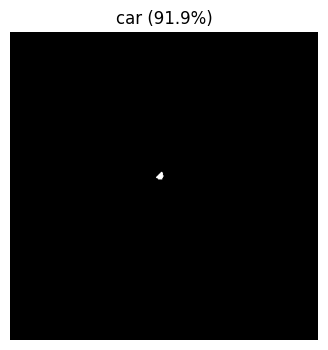

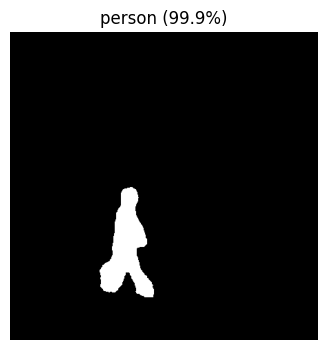

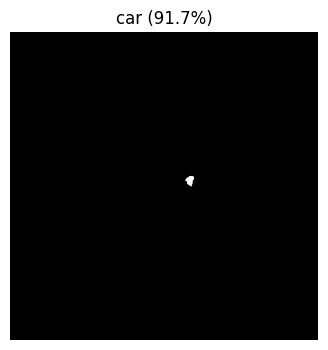

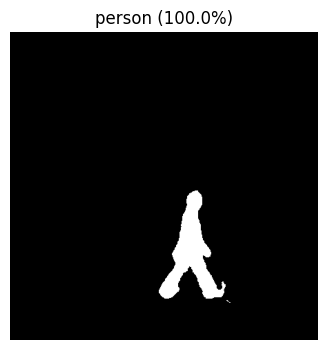

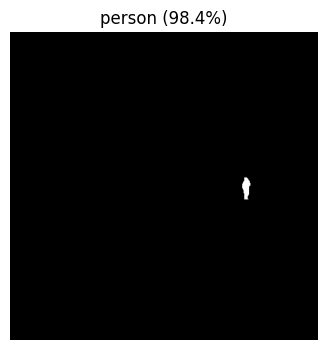

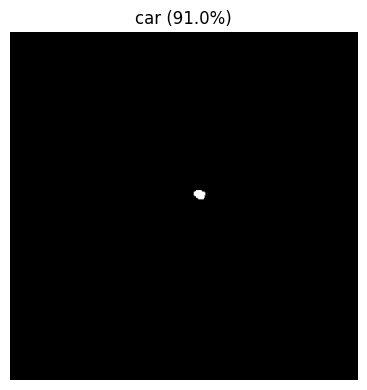

In [56]:
import matplotlib.pyplot as plt

for i, seg in enumerate(segments):
    fig, axes = plt.subplots(1, 1, figsize=(4, 4))
    axes.imshow(seg["mask"], cmap="gray")
    axes.set_title(f"{seg['label']} ({seg['score']:.1%})")
    axes.axis("off")

plt.tight_layout()
plt.show()

In [31]:
segments

[{'score': 0.982718,
  'label': 'cake',
  'mask': <PIL.Image.Image image mode=L size=768x768>}]

## 8. *Text to image*

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


scheduler_config.json:   0%|          | 0.00/313 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

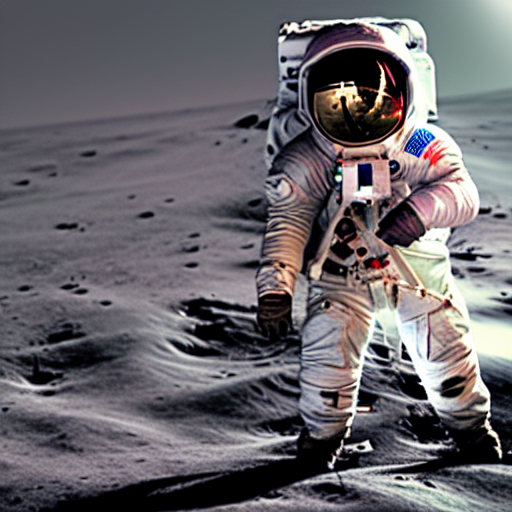

In [66]:
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# Usando o modelo clássico v1-4 que possui acesso 100% público e direto sem necessidade de token
model_id = "CompVis/stable-diffusion-v1-4"
scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")
pipe = StableDiffusionPipeline.from_pretrained(model_id, scheduler=scheduler, torch_dtype=torch.float16)
pipe = pipe.to("cuda")

prompt = "An astronaut playing guitar on the moon, digital art"
image = pipe(prompt).images[0]

# Exibe a imagem gerada
image

### Geração com Autenticação

Alguns modelos como o `stable-diffusion-v1-5/stable-diffusion-v1-5` podem exigir criar uma conta no [Hugging Face](https://huggingface.co/) e ainda aceitar os termos de uso na página do modelo ou mesmo fazer a solicitação de acesso. Nesse caso é necessário gerar um **Token de Acesso** (com permissão de leitura) em suas configurações de perfil (*Settings -> Access Tokens*).

  0%|          | 0/50 [00:00<?, ?it/s]

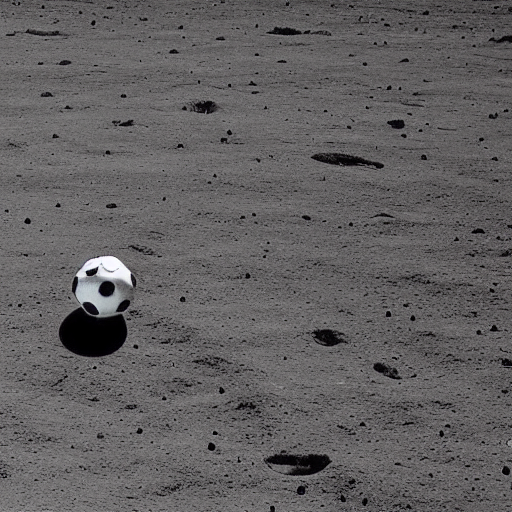

In [78]:
from huggingface_hub import notebook_login
import torch
from diffusers import StableDiffusionPipeline, EulerDiscreteScheduler

# 1. Execute esta função para abrir o campo de login e colar seu Token do Hugging Face
notebook_login()

# 2. Uma vez autenticado, você poderá carregar o modelo restrito normalmente
model_id = "stable-diffusion-v1-5/stable-diffusion-v1-5"
scheduler = EulerDiscreteScheduler.from_pretrained(model_id, subfolder="scheduler")
pipe = StableDiffusionPipeline.from_pretrained(model_id, scheduler=scheduler, torch_dtype=torch.float16)
pipe = pipe.to("cuda")

prompt = "Draw an astronaut playing soccer on the moon."
image_output = pipe(prompt).images[0]

# Exibe a imagem
image_output